# 01 — Análisis general y depuración básica del dataset

En éste notebook se realiza lo siguiente:

1. Examinar la estructura general del dataset original;
2. Analizar exhaustivamente los valores faltantes;
3. Generar una versión del dataset depurado básico, sin modificar el dataset original.

**Criterio de faltantes:** celdas vacías, cadenas vacías, `"-"` y `"_"`.  
El valor `0` se conserva como dato válido.

## 1. Importación de librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from google.colab import files
from IPython.display import display

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 200)

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 2. Carga del archivo Excel

In [2]:
uploaded = files.upload()

if not uploaded:
    raise ValueError("No se seleccionó ningún archivo.")

ruta_archivo = next(iter(uploaded))
print(f"Archivo cargado: {ruta_archivo}")

Saving DataSet.xlsx to DataSet.xlsx
Archivo cargado: DataSet.xlsx


## 3. Lectura y conservación del dataset original

In [3]:
excel = pd.ExcelFile(ruta_archivo)
print("Hojas encontradas:", excel.sheet_names)

hoja = excel.sheet_names[0]
df_original = pd.read_excel(ruta_archivo, sheet_name=hoja)

# Copia de trabajo para el análisis; df_original no se modifica.
df = df_original.copy()

print(f"Hoja leída: {hoja}")
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")

display(df.head())

Hojas encontradas: ['Hoja1']
Hoja leída: Hoja1
Filas: 978
Columnas: 125


,alumno,nota,tecnologia_pc_casa,tecnologia_pc_trabajo,tecnologia_pc_universidad,tecnologia_pc_otro_lugar,tecnologia_int_casa,tecnologia_int_trabajo,tecnologia_int_universidad,tecnologia_int_otro_lugar,deportes,deportes_universidad,deportes_gimnasio,deportes_particular,deportes_otro_lugar,deportes_basquet,deportes_futbol,deportes_gimnasia,deportes_handball,deportes_natacion,deportes_tenis,deportes_voley,deportes_otros,nivel_idioma_ingles,nivel_idioma_aleman,nivel_idioma_frances,nivel_idioma_italiano,nivel_idioma_portugues,nivel_idioma_chino,idioma_otro,nivel_idioma_otro,tecnologia_int_movil,condicion_discapacidad,tiene_cud,disc_auditiva,aud_tipo,aud_lenguaje_senias,aud_lenguaje_labial,aud_comunicacion_otra,aud_apoyo_vida_diaria,aud_req_interprete_lengua_senias,aud_req_aro_magnetico,aud_req_otros_apoyos,aud_otros_apoyos,disc_visual,vis_dificultad_para_ver,vis_apoyo_vida_diaria,vis_req_archivo_audio,vis_req_texto_digital,vis_req_texto_braile,vis_req_otros_apoyos,vis_otros_apoyos,disc_motora,mot_apoyo_vida_diaria,mot_req_apoyo_aula,mot_apoyo_aula,mot_req_otros_apoyos,mot_otros_apoyos,disc_cond_psicosocial,psi_descripcion,psi_apoyo_vida_diaria,psi_req_otros_apoyos,psi_otros_apoyos,disc_otra,otra_descripcion,otra_req_apoyo_vida_diaria,otra_apoyo_vida_diaria,informacion_importante,costeo_estudios_familiar,costeo_estudios_plan_social,costeo_estudios_trabajo,costeo_estudios_beca,costeo_estudios_otro,costeo_estudios_descripcion,beca,beca_fuente_universidad,beca_fuente_nacional,beca_fuente_provincial,beca_fuente_municipal,beca_fuente_internacional,beca_fuente_otra,beca_tipo_economica,beca_tipo_servicios,beca_tipo_investigacion,beca_economica_transporte,beca_economica_efectivo,beca_economica_fotocopias,beca_economica_habitacional,beca_economica_comedor,trabajo_existe,trabajo_hace,trabajo_familiar,trabajo_con_descuentos_jubilatorios,trabajo_recibe_pago,trabajo_ocupacion,trabajo_hora_sem,trabajo_carrera,trabajo_tarea_descripcion,estado_civil,unido_hecho,situacion_padre,situacion_madre,cantidad_hijos,cantidad_familia,turno_preferido,cobertura_salud,tipo_vivienda,vive_con,procedencia_calle,procedencia_numero,procedencia_piso,procedencia_departamento,procedencia_unidad,procedencia_localidad,procedencia_barrio,procedencia_codigo_postal,es_celiaco,mot_vocacion,mot_sugerencia_familiar,mot_reconocimiento_social,mot_insercion_laboral,mot_perfil_profesional,mot_mejora_economica,mot_util_sociedad,mot_otros_p
0,25342,A,S,S,S,N,S,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,3.0,4.0,4.0,4.0,4.0,NaN,NaN,NaN,N,N,N,N,1,N,N,NaN,NaN,N,N,N,NaN,N,1,NaN,N,N,N,N,NaN,N,NaN,N,NaN,N,NaN,N,NaN,NaN,N,NaN,N,NaN,N,NaN,NaN,S,N,S,N,N,NaN,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,1,2.0,S,N,N,1.0,4.0,1.0,NaN,2,N,V,V,0,0,3.0,2,5.0,3.0,Jose Hernandez 525,525,0,0,0,5436,Hipotecario,3530.0,N,N,S,N,N,N,N,N,N
1,25567,R,S,N,S,N,S,N,S,N,N,N,N,N,N,N,N,N,N,N,N,N,N,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN,S,N,N,N,1,N,N,NaN,NaN,N,N,N,NaN,N,1,NaN,N,N,N,N,NaN,N,NaN,N,NaN,N,NaN,N,NaN,NaN,N,NaN,N,NaN,N,NaN,NaN,N,N,N,N,N,NaN,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,1,3.0,S,N,S,2.0,2.0,3.0,NaN,1,N,N,V,0,0,NaN,1,NaN,NaN,17 Entre 0 Y 00 Superiora Palmira,172,_,_,_,6036,_,3700.0,N,N,N,N,N,N,N,N,N
2,28277,U,S,N,N,N,S,N,N,N,S,N,N,S,N,N,N,N,N,N,N,N,S,3.0,4.0,3.0,4.0,3.0,NaN,NaN,NaN,S,N,N,N,1,N,N,NaN,NaN,N,N,N,NaN,N,1,NaN,N,N,N,N,NaN,N,NaN,N,NaN,N,NaN,N,NaN,NaN,N,NaN,N,NaN,N,NaN,NaN,S,N,S,N,N,NaN,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,1,2.0,N,N,N,2.0,3.0,NaN,Compra Y Venta,1,N,V,V,0,3,1.0,5,5.0,3.0,San JosÃ©,10,-,-,-,5342,San JosÃ©,3514.0,N,N,N,N,S,N,N,N,N
3,27014,A,S,N,S,N,S,N,S,N,S,N,N,S,N,S,N,N,N,N,N,N,N,3.0,4.0,4.0,4.0,4.0,4.0,NaN,NaN,S,N,N,N,1,N,N,NaN,NaN,N,N,N,NaN,N,1,NaN,N,N,N,N,NaN,N,NaN,N,NaN,N,NaN,N,NaN,NaN,N,NaN,N,NaN,N,NaN,NaN,S,N,S,N,N,NaN,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,1,2.0,N,N,N,2.0,3.0,2.0,TÃ©cnico InformÃ¡tico,1,N,V,V,0,0,1.0,5,6.0,3.0,Mza 4 Pc 11,-,-,-,-,6167,Victor Arrudi,3730.0,N,N,S,S,S,S,S,S,N
4,32446,R,S,N,N,N,S,N,N,S,S,N,N,S,N,N,N,N,N,N,N,S,N,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,S,N,N,N,1,N,N,NaN,NaN,N,N,N,NaN,N,1,NaN,N,N,N,N,NaN,N

## 4. Estructura general del dataset

In [4]:
resumen_estructura = pd.DataFrame({
    "variable": df.columns,
    "tipo_dato_pandas": [str(df[col].dtype) for col in df.columns],
    "valores_unicos": [df[col].nunique(dropna=True) for col in df.columns]
})

print("Información general:")
print(f"Duplicados exactos: {df.duplicated().sum()}")
display(resumen_estructura)

Información general:
Duplicados exactos: 380


,variable,tipo_dato_pandas,valores_unicos
0,alumno,int64,343
1,nota,object,3
2,tecnologia_pc_casa,object,2
3,tecnologia_pc_trabajo,object,2
4,tecnologia_pc_universidad,object,2
5,tecnologia_pc_otro_lugar,object,2
6,tecnologia_int_casa,object,2
7,tecnologia_int_trabajo,object,2
8,tecnologia_int_universidad,object,2
9,tecnologia_int_otro_lugar,object,2


## 5. Funciones para detectar valores faltantes

In [5]:
def mascara_valores_faltantes(serie):
    """Devuelve True para NaN, texto vacío, '-' o '_'."""
    s_str = serie.astype("string").str.strip()

    return (
        serie.isna()
        | s_str.eq("")
        | s_str.eq("-")
        | s_str.eq("_")
    )


def contar_componentes_faltantes(serie):
    """Cuenta por separado los componentes definidos como faltantes."""
    s_str = serie.astype("string").str.strip()

    vacias = (serie.isna() | s_str.eq("")).sum()
    guion = s_str.eq("-").sum()
    guion_bajo = s_str.eq("_").sum()
    total = mascara_valores_faltantes(serie).sum()

    return int(vacias), int(guion), int(guion_bajo), int(total)


print("Funciones definidas correctamente.")

Funciones definidas correctamente.


## 6. Resumen general de valores faltantes

In [6]:
total_filas, total_columnas = df.shape
total_celdas = total_filas * total_columnas

vacias_total = 0
guion_total = 0
guion_bajo_total = 0
faltantes_total = 0

for col in df.columns:
    vacias, guion, guion_bajo, total = contar_componentes_faltantes(df[col])
    vacias_total += vacias
    guion_total += guion
    guion_bajo_total += guion_bajo
    faltantes_total += total

porcentaje_faltantes = (
    faltantes_total / total_celdas * 100
    if total_celdas > 0 else 0
)

resumen_general = pd.DataFrame({
    "concepto": [
        "Filas totales",
        "Columnas totales",
        "Celdas totales",
        "Celdas vacías",
        "Celdas con '-'",
        "Celdas con '_'",
        "Valores faltantes totales",
        "Porcentaje de valores faltantes"
    ],
    "valor": [
        total_filas,
        total_columnas,
        total_celdas,
        vacias_total,
        guion_total,
        guion_bajo_total,
        faltantes_total,
        round(porcentaje_faltantes, 2)
    ]
})

display(resumen_general)

,concepto,valor
0,Filas totales,978.00
1,Columnas totales,125.00
2,Celdas totales,122250.00
3,Celdas vacías,23782.00
4,Celdas con '-',759.00
5,Celdas con '_',8.00
6,Valores faltantes totales,24549.00
7,Porcentaje de valores faltantes,20.08


## 7. Análisis de faltantes por variable

In [7]:
analisis_columnas = []

for col in df.columns:
    serie = df[col]
    vacias, guion, guion_bajo, total = contar_componentes_faltantes(serie)
    mascara = mascara_valores_faltantes(serie)

    valores_no_faltantes = serie[~mascara]
    no_faltantes = len(serie) - total
    valores_unicos = valores_no_faltantes.nunique(dropna=True)

    moda = valores_no_faltantes.mode(dropna=True)
    valor_mas_frecuente = moda.iloc[0] if not moda.empty else np.nan

    analisis_columnas.append({
        "variable": col,
        "tipo_dato_pandas": str(serie.dtype),
        "total_registros": len(serie),
        "vacias": vacias,
        "guion": guion,
        "guion_bajo": guion_bajo,
        "faltantes_total": total,
        "porcentaje_faltantes": round(total / len(serie) * 100, 2) if len(serie) else 0,
        "no_faltantes": no_faltantes,
        "porcentaje_no_faltantes": round(no_faltantes / len(serie) * 100, 2) if len(serie) else 0,
        "valores_unicos_no_faltantes": int(valores_unicos),
        "valor_mas_frecuente_no_faltante": valor_mas_frecuente
    })

df_faltantes = (
    pd.DataFrame(analisis_columnas)
    .sort_values(
        by=["faltantes_total", "porcentaje_faltantes"],
        ascending=False
    )
    .reset_index(drop=True)
)

display(df_faltantes.head(30))

,variable,tipo_dato_pandas,total_registros,vacias,guion,guion_bajo,faltantes_total,porcentaje_faltantes,no_faltantes,porcentaje_no_faltantes,valores_unicos_no_faltantes,valor_mas_frecuente_no_faltante
0,aud_comunicacion_otra,float64,978,978,0,0,978,100.00,0,0.00,0,NaN
1,aud_apoyo_vida_diaria,float64,978,978,0,0,978,100.00,0,0.00,0,NaN
2,aud_otros_apoyos,float64,978,978,0,0,978,100.00,0,0.00,0,NaN
3,vis_otros_apoyos,float64,978,978,0,0,978,100.00,0,0.00,0,NaN
4,mot_apoyo_aula,float64,978,978,0,0,978,100.00,0,0.00,0,NaN
5,mot_otros_apoyos,float64,978,978,0,0,978,100.00,0,0.00,0,NaN
6,psi_descripcion,float64,978,978,0,0,978,100.00,0,0.00,0,NaN
7,psi_apoyo_vida_diaria,float64,978,978,0,0,978,100.00,0,0.00,0,NaN
8,psi_otros_apoyos,float64,978,978,0,0,978,100.00,0,0.00,0,NaN
9,otra_apoyo_vida_diaria,float64,978,978,0,0,978,100.00,0,0.00,0,NaN


## 8. Variables completas y completamente vacías

In [8]:
variables_sin_faltantes = df_faltantes[
    df_faltantes["faltantes_total"] == 0
].copy()

variables_100_faltantes = df_faltantes[
    df_faltantes["porcentaje_faltantes"] == 100
].copy()

print(f"Variables sin faltantes: {len(variables_sin_faltantes)}")
print(f"Variables con 100% de faltantes: {len(variables_100_faltantes)}")

display(variables_sin_faltantes[
    ["variable", "tipo_dato_pandas", "valores_unicos_no_faltantes"]
])

display(variables_100_faltantes[
    ["variable", "faltantes_total", "porcentaje_faltantes"]
])

Variables sin faltantes: 84
Variables con 100% de faltantes: 10


,variable,tipo_dato_pandas,valores_unicos_no_faltantes
41,alumno,int64,343
42,nota,object,3
43,tecnologia_pc_casa,object,2
44,tecnologia_pc_trabajo,object,2
45,tecnologia_pc_universidad,object,2
46,tecnologia_pc_otro_lugar,object,2
47,deportes,object,2
48,deportes_universidad,object,2
49,deportes_gimnasio,object,2
50,deportes_particular,object,2


,variable,faltantes_total,porcentaje_faltantes
0,aud_comunicacion_otra,978,100.0
1,aud_apoyo_vida_diaria,978,100.0
2,aud_otros_apoyos,978,100.0
3,vis_otros_apoyos,978,100.0
4,mot_apoyo_aula,978,100.0
5,mot_otros_apoyos,978,100.0
6,psi_descripcion,978,100.0
7,psi_apoyo_vida_diaria,978,100.0
8,psi_otros_apoyos,978,100.0
9,otra_apoyo_vida_diaria,978,100.0


## 9. Distribución de variables según su porcentaje de faltantes

In [9]:
def clasificar_rango_faltantes(p):
    if p == 0:
        return "0% faltantes"
    if p == 100:
        return "100% faltantes"
    if 90 <= p < 100:
        return "90% a 99%"
    if 75 <= p < 90:
        return "75% a 89%"
    if 50 <= p < 75:
        return "50% a 74%"
    if 25 <= p < 50:
        return "25% a 49%"
    if 1 <= p < 25:
        return "1% a 24%"
    return "Menos de 1%"


orden_rangos = [
    "100% faltantes",
    "90% a 99%",
    "75% a 89%",
    "50% a 74%",
    "25% a 49%",
    "1% a 24%",
    "Menos de 1%",
    "0% faltantes"
]

df_faltantes["rango_faltantes"] = (
    df_faltantes["porcentaje_faltantes"]
    .apply(clasificar_rango_faltantes)
)

resumen_rangos = (
    df_faltantes["rango_faltantes"]
    .value_counts()
    .reindex(orden_rangos, fill_value=0)
    .rename_axis("rango_faltantes")
    .reset_index(name="cantidad_variables")
)

display(resumen_rangos)

,rango_faltantes,cantidad_variables
0,100% faltantes,10
1,90% a 99%,12
2,75% a 89%,0
3,50% a 74%,0
4,25% a 49%,6
5,1% a 24%,7
6,Menos de 1%,6
7,0% faltantes,84


## 10. Gráficos de valores faltantes

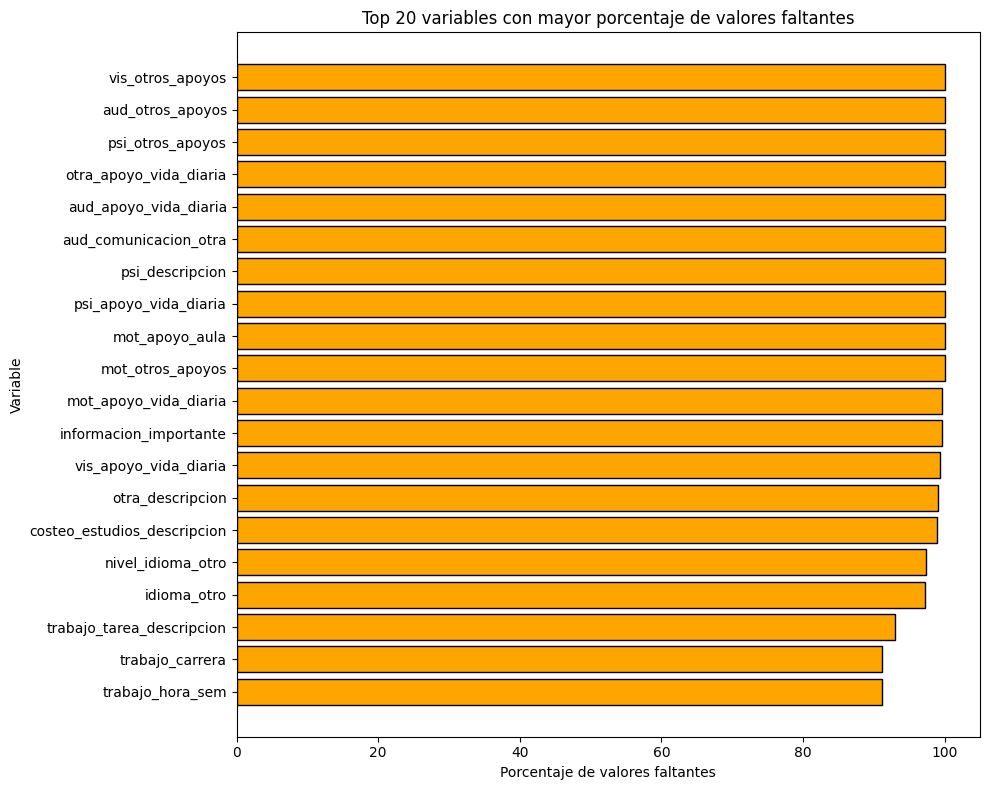

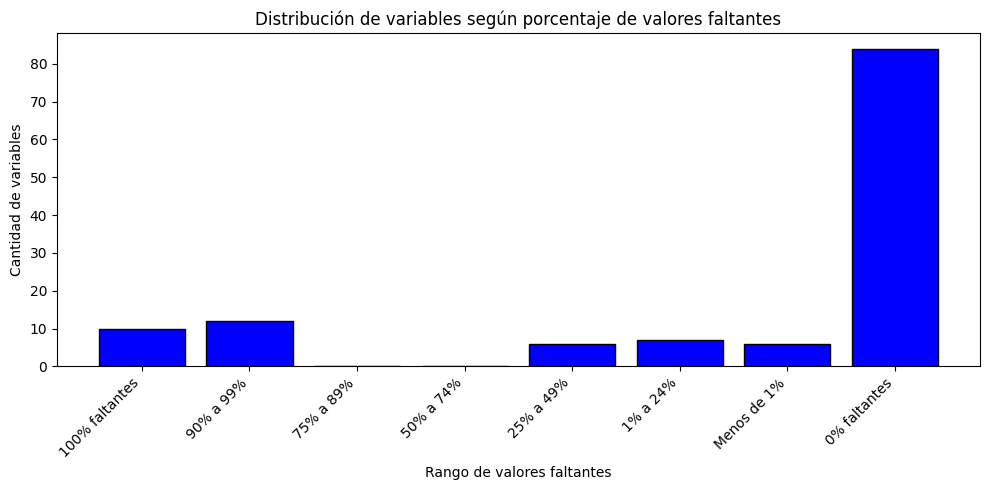

In [10]:
carpeta_salida = Path("salidas_analisis_dataset")
carpeta_salida.mkdir(parents=True, exist_ok=True)

# Gráfico 1: naranja
top20 = (
    df_faltantes
    .head(20)
    .sort_values("porcentaje_faltantes", ascending=True)
)

plt.figure(figsize=(10, 8))
plt.barh(
    top20["variable"],
    top20["porcentaje_faltantes"],
    color="orange",
    edgecolor="black"
)
plt.xlabel("Porcentaje de valores faltantes")
plt.ylabel("Variable")
plt.title("Top 20 variables con mayor porcentaje de valores faltantes")
plt.tight_layout()
plt.savefig(
    carpeta_salida / "top20_variables_faltantes.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# Gráfico 2: azul
plt.figure(figsize=(10, 5))
plt.bar(
    resumen_rangos["rango_faltantes"].astype(str),
    resumen_rangos["cantidad_variables"],
    color="blue",
    edgecolor="black"
)
plt.xlabel("Rango de valores faltantes")
plt.ylabel("Cantidad de variables")
plt.title("Distribución de variables según porcentaje de valores faltantes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(
    carpeta_salida / "distribucion_rangos_faltantes.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

## 11. Análisis de faltantes por fila

In [11]:
mascara_faltantes_df = df.apply(mascara_valores_faltantes)

df_faltantes_fila = pd.DataFrame({
    "indice_fila": df.index,
    "faltantes_total": mascara_faltantes_df.sum(axis=1).astype(int)
})

df_faltantes_fila["porcentaje_faltantes"] = (
    df_faltantes_fila["faltantes_total"] / total_columnas * 100
).round(2)

print("Resumen de faltantes por fila:")
display(df_faltantes_fila["faltantes_total"].describe())

display(
    df_faltantes_fila
    .sort_values("faltantes_total", ascending=False)
    .head(20)
)

Resumen de faltantes por fila:


,faltantes_total
count,978.000000
mean,25.101227
std,3.281875
min,14.000000
25%,22.000000
50%,25.000000
75%,28.000000
max,34.000000


,indice_fila,faltantes_total,porcentaje_faltantes
964,964,34,27.2
899,899,34,27.2
850,850,33,26.4
915,915,33,26.4
956,956,33,26.4
354,354,33,26.4
311,311,33,26.4
7,7,33,26.4
891,891,33,26.4
842,842,32,25.6


## 12. Exportación del informe del análisis

In [12]:
archivo_reporte = carpeta_salida / "analisis_general_dataset.xlsx"

with pd.ExcelWriter(archivo_reporte, engine="openpyxl") as writer:
    resumen_general.to_excel(writer, sheet_name="Resumen_general", index=False)
    resumen_estructura.to_excel(writer, sheet_name="Estructura", index=False)
    df_faltantes.to_excel(writer, sheet_name="Faltantes_variable", index=False)
    resumen_rangos.to_excel(writer, sheet_name="Rangos_faltantes", index=False)
    df_faltantes_fila.to_excel(writer, sheet_name="Faltantes_fila", index=False)
    variables_sin_faltantes.to_excel(writer, sheet_name="Sin_faltantes", index=False)
    variables_100_faltantes.to_excel(writer, sheet_name="100pct_faltantes", index=False)

print(f"Reporte generado: {archivo_reporte}")
files.download(str(archivo_reporte))

Reporte generado: salidas_analisis_dataset/analisis_general_dataset.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Depuración básica

Se crea `df_depurado` a partir de `df_original`. Solo se normalizan espacios y representaciones de faltantes.  
No se eliminan filas, columnas ni valores válidos.

In [13]:
df_depurado = df_original.copy()

# Quitar espacios al inicio y al final en columnas de texto.
for col in df_depurado.select_dtypes(include=["object", "string"]).columns:
    df_depurado[col] = df_depurado[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Reemplazar únicamente los símbolos definidos como faltantes.
df_depurado = df_depurado.replace(["", "-", "_"], np.nan)

print("Depuración básica finalizada.")
print(f"Filas: {df_depurado.shape[0]}")
print(f"Columnas: {df_depurado.shape[1]}")
display(df_depurado.head())

Depuración básica finalizada.
Filas: 978
Columnas: 125


,alumno,nota,tecnologia_pc_casa,tecnologia_pc_trabajo,tecnologia_pc_universidad,tecnologia_pc_otro_lugar,tecnologia_int_casa,tecnologia_int_trabajo,tecnologia_int_universidad,tecnologia_int_otro_lugar,deportes,deportes_universidad,deportes_gimnasio,deportes_particular,deportes_otro_lugar,deportes_basquet,deportes_futbol,deportes_gimnasia,deportes_handball,deportes_natacion,deportes_tenis,deportes_voley,deportes_otros,nivel_idioma_ingles,nivel_idioma_aleman,nivel_idioma_frances,nivel_idioma_italiano,nivel_idioma_portugues,nivel_idioma_chino,idioma_otro,nivel_idioma_otro,tecnologia_int_movil,condicion_discapacidad,tiene_cud,disc_auditiva,aud_tipo,aud_lenguaje_senias,aud_lenguaje_labial,aud_comunicacion_otra,aud_apoyo_vida_diaria,aud_req_interprete_lengua_senias,aud_req_aro_magnetico,aud_req_otros_apoyos,aud_otros_apoyos,disc_visual,vis_dificultad_para_ver,vis_apoyo_vida_diaria,vis_req_archivo_audio,vis_req_texto_digital,vis_req_texto_braile,vis_req_otros_apoyos,vis_otros_apoyos,disc_motora,mot_apoyo_vida_diaria,mot_req_apoyo_aula,mot_apoyo_aula,mot_req_otros_apoyos,mot_otros_apoyos,disc_cond_psicosocial,psi_descripcion,psi_apoyo_vida_diaria,psi_req_otros_apoyos,psi_otros_apoyos,disc_otra,otra_descripcion,otra_req_apoyo_vida_diaria,otra_apoyo_vida_diaria,informacion_importante,costeo_estudios_familiar,costeo_estudios_plan_social,costeo_estudios_trabajo,costeo_estudios_beca,costeo_estudios_otro,costeo_estudios_descripcion,beca,beca_fuente_universidad,beca_fuente_nacional,beca_fuente_provincial,beca_fuente_municipal,beca_fuente_internacional,beca_fuente_otra,beca_tipo_economica,beca_tipo_servicios,beca_tipo_investigacion,beca_economica_transporte,beca_economica_efectivo,beca_economica_fotocopias,beca_economica_habitacional,beca_economica_comedor,trabajo_existe,trabajo_hace,trabajo_familiar,trabajo_con_descuentos_jubilatorios,trabajo_recibe_pago,trabajo_ocupacion,trabajo_hora_sem,trabajo_carrera,trabajo_tarea_descripcion,estado_civil,unido_hecho,situacion_padre,situacion_madre,cantidad_hijos,cantidad_familia,turno_preferido,cobertura_salud,tipo_vivienda,vive_con,procedencia_calle,procedencia_numero,procedencia_piso,procedencia_departamento,procedencia_unidad,procedencia_localidad,procedencia_barrio,procedencia_codigo_postal,es_celiaco,mot_vocacion,mot_sugerencia_familiar,mot_reconocimiento_social,mot_insercion_laboral,mot_perfil_profesional,mot_mejora_economica,mot_util_sociedad,mot_otros_p
0,25342,A,S,S,S,N,S,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,3.0,4.0,4.0,4.0,4.0,NaN,NaN,NaN,N,N,N,N,1,N,N,NaN,NaN,N,N,N,NaN,N,1,NaN,N,N,N,N,NaN,N,NaN,N,NaN,N,NaN,N,NaN,NaN,N,NaN,N,NaN,N,NaN,NaN,S,N,S,N,N,NaN,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,1,2.0,S,N,N,1.0,4.0,1.0,NaN,2,N,V,V,0,0,3.0,2,5.0,3.0,Jose Hernandez 525,525,0,0,0,5436,Hipotecario,3530.0,N,N,S,N,N,N,N,N,N
1,25567,R,S,N,S,N,S,N,S,N,N,N,N,N,N,N,N,N,N,N,N,N,N,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN,S,N,N,N,1,N,N,NaN,NaN,N,N,N,NaN,N,1,NaN,N,N,N,N,NaN,N,NaN,N,NaN,N,NaN,N,NaN,NaN,N,NaN,N,NaN,N,NaN,NaN,N,N,N,N,N,NaN,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,1,3.0,S,N,S,2.0,2.0,3.0,NaN,1,N,N,V,0,0,NaN,1,NaN,NaN,17 Entre 0 Y 00 Superiora Palmira,172,NaN,NaN,NaN,6036,NaN,3700.0,N,N,N,N,N,N,N,N,N
2,28277,U,S,N,N,N,S,N,N,N,S,N,N,S,N,N,N,N,N,N,N,N,S,3.0,4.0,3.0,4.0,3.0,NaN,NaN,NaN,S,N,N,N,1,N,N,NaN,NaN,N,N,N,NaN,N,1,NaN,N,N,N,N,NaN,N,NaN,N,NaN,N,NaN,N,NaN,NaN,N,NaN,N,NaN,N,NaN,NaN,S,N,S,N,N,NaN,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,1,2.0,N,N,N,2.0,3.0,NaN,Compra Y Venta,1,N,V,V,0,3,1.0,5,5.0,3.0,San JosÃ©,10,NaN,NaN,NaN,5342,San JosÃ©,3514.0,N,N,N,N,S,N,N,N,N
3,27014,A,S,N,S,N,S,N,S,N,S,N,N,S,N,S,N,N,N,N,N,N,N,3.0,4.0,4.0,4.0,4.0,4.0,NaN,NaN,S,N,N,N,1,N,N,NaN,NaN,N,N,N,NaN,N,1,NaN,N,N,N,N,NaN,N,NaN,N,NaN,N,NaN,N,NaN,NaN,N,NaN,N,NaN,N,NaN,NaN,S,N,S,N,N,NaN,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,1,2.0,N,N,N,2.0,3.0,2.0,TÃ©cnico InformÃ¡tico,1,N,V,V,0,0,1.0,5,6.0,3.0,Mza 4 Pc 11,NaN,NaN,NaN,NaN,6167,Victor Arrudi,3730.0,N,N,S,S,S,S,S,S,N
4,32446,R,S,N,N,N,S,N,N,S,S,N,N,S,N,N,N,N,N,N,N,S,N,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,S,N,N,N,1,N,N,NaN,NaN,N,N,N,NaN

## 14. Verificación del dataset depurado

In [14]:
filas, columnas = df_depurado.shape
total_celdas_depurado = filas * columnas
total_faltantes_depurado = int(df_depurado.isna().sum().sum())

porcentaje_faltantes_depurado = (
    total_faltantes_depurado / total_celdas_depurado * 100
    if total_celdas_depurado else 0
)

print(f"Filas: {filas}")
print(f"Columnas: {columnas}")
print(f"Celdas totales: {total_celdas_depurado}")
print(f"Valores faltantes: {total_faltantes_depurado}")
print(f"Porcentaje de faltantes: {porcentaje_faltantes_depurado:.2f}%")

if "nota" in df_depurado.columns:
    distribucion_nota = (
        df_depurado["nota"]
        .value_counts(dropna=False)
        .rename_axis("nota")
        .reset_index(name="cantidad")
    )
    distribucion_nota["porcentaje"] = (
        distribucion_nota["cantidad"] / len(df_depurado) * 100
    ).round(2)

    print("\nDistribución de la variable objetivo 'nota':")
    display(distribucion_nota)
else:
    print("\nAdvertencia: no se encontró la columna 'nota'.")

Filas: 978
Columnas: 125
Celdas totales: 122250
Valores faltantes: 24549
Porcentaje de faltantes: 20.08%

Distribución de la variable objetivo 'nota':


,nota,cantidad,porcentaje
0,R,451,46.11
1,A,279,28.53
2,U,248,25.36


## 15. Exportación del dataset depurado básico

In [15]:
nombre_salida_excel = "DataSet_depurado_basico_EDA.xlsx"

with pd.ExcelWriter(nombre_salida_excel, engine="openpyxl") as writer:
    df_depurado.to_excel(
        writer,
        sheet_name="Datos_depurados",
        index=False
    )

print(f"Archivo generado: {nombre_salida_excel}")
files.download(nombre_salida_excel)

Archivo generado: DataSet_depurado_basico_EDA.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>